In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor

# Load the dataset
df = pd.read_csv("/Users/kshitijsharma/Old Documents/College/Surbhi ma'am work/Final work/Feature Extraction/combined_features.csv")

# Parse the standardized features
df['Combined_Features'] = df['Combined_Features'].apply(eval)

# Convert features to a NumPy array
X = np.array(df['Combined_Features'].tolist())
y = df['Class_Label'].values

# Define the objective function for feature selection
def objective_function(mask):
    selected_features = np.where(mask > 0.5)[0]
    if len(selected_features) == 0:
        return 1.0  # Penalize empty feature subsets
    X_selected = X[:, selected_features]
    X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.3, random_state=42)
    clf = RandomForestClassifier()
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    return 1 - accuracy  # Minimize the inverse of accuracy

# Define the Grey Wolf Optimizer with parallel processing
class GreyWolfOptimizer:
    def __init__(self, obj_func, dim, bounds, max_iter, population_size, n_jobs=4):
        self.obj_func = obj_func
        self.dim = dim
        self.bounds = bounds
        self.max_iter = max_iter
        self.population_size = population_size
        self.n_jobs = n_jobs
        self.population = np.random.uniform(bounds[0], bounds[1], (population_size, dim))
        self.alpha, self.beta, self.delta = np.zeros((3, dim))
        self.alpha_score = self.beta_score = self.delta_score = float('inf')

    def evaluate_population(self):
        with ThreadPoolExecutor(max_workers=self.n_jobs) as executor:
            fitness = np.array(list(executor.map(self.obj_func, self.population)))
        return fitness

    def update_wolves(self, a, iter_num):
        new_population = np.copy(self.population)
        for i in range(self.population_size):
            for j in range(self.dim):
                r1, r2 = np.random.rand(), np.random.rand()
                A1 = 2 * a * r1 - a
                C1 = 2 * r2

                D_alpha = abs(C1 * self.alpha[j] - self.population[i][j])
                X1 = self.alpha[j] - A1 * D_alpha

                r1, r2 = np.random.rand(), np.random.rand()
                A2 = 2 * a * r1 - a
                C2 = 2 * r2

                D_beta = abs(C2 * self.beta[j] - self.population[i][j])
                X2 = self.beta[j] - A2 * D_beta

                r1, r2 = np.random.rand(), np.random.rand()
                A3 = 2 * a * r1 - a
                C3 = 2 * r2

                D_delta = abs(C3 * self.delta[j] - self.population[i][j])
                X3 = self.delta[j] - A3 * D_delta

                new_population[i][j] = (X1 + X2 + X3) / 3

            new_population[i] = np.clip(new_population[i], self.bounds[0], self.bounds[1])
        return new_population

    def optimize(self):
        fitness = self.evaluate_population()
        sorted_indices = np.argsort(fitness)
        self.alpha, self.beta, self.delta = self.population[sorted_indices[:3]]
        self.alpha_score, self.beta_score, self.delta_score = fitness[sorted_indices[:3]]

        for iter_num in tqdm(range(self.max_iter), desc="Optimizing"):
            a = 2 - iter_num * (2 / self.max_iter)
            self.population = self.update_wolves(a, iter_num)
            fitness = self.evaluate_population()
            sorted_indices = np.argsort(fitness)

            if fitness[sorted_indices[0]] < self.alpha_score:
                self.alpha, self.beta, self.delta = self.population[sorted_indices[:3]]
                self.alpha_score, self.beta_score, self.delta_score = fitness[sorted_indices[:3]]

        return self.alpha, self.alpha_score

# Set parameters
dim = X.shape[1]
bounds = [0, 1]
max_iter = 100
population_size = 20
n_jobs = 8  # Number of parallel workers

# Initialize and run the optimizer
gwo = GreyWolfOptimizer(objective_function, dim, bounds, max_iter, population_size, n_jobs=n_jobs)
best_mask, best_fitness = gwo.optimize()

# Extract the selected features
selected_features = np.where(best_mask > 0.5)[0]
df['Selected_Features'] = df['Combined_Features'].apply(lambda x: [x[i] for i in selected_features])

# Save the new CSV
df[['Image_Index', 'Class_Label', 'Selected_Features']].to_csv('GWO_selected_features.csv', index=False)

print("Feature selection completed and new dataset saved!")


Optimizing: 100%|██████████| 100/100 [02:47<00:00,  1.67s/it]

Feature selection completed and new dataset saved!


In [2]:
import pandas as pd

# Load original and selected datasets
original_df = pd.read_csv("/Users/kshitijsharma/Old Documents/College/Surbhi ma'am work/Final work/Feature Extraction/combined_features.csv")
selected_df = pd.read_csv('GWO_selected_features.csv')

# Extract and count features
original_features_count = len(eval(original_df['Combined_Features'][0]))
selected_features_count = len(eval(selected_df['Selected_Features'][0]))

# Compare number of features
print(f"Original number of features: {original_features_count}")
print(f"Selected number of features: {selected_features_count}")

reduction_percentage = ((original_features_count - selected_features_count) / original_features_count) * 100
print(f"Feature reduction: {reduction_percentage:.2f}%")

Original number of features: 199
Selected number of features: 68
Feature reduction: 65.83%


# ML

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, Flatten, MaxPooling1D, Dropout
import matplotlib.pyplot as plt
import seaborn as sns

# Load CSV
data = pd.read_csv("GWO_selected_features.csv")

# Parse features
features = data['Selected_Features'].apply(lambda x: np.array(eval(x))).tolist()
X = np.array(features)
y = data['Class_Label']

# Encode class labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Helper function to evaluate models
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, average='weighted'))
    print("Recall:", recall_score(y_test, y_pred, average='weighted'))
    print("F1 Score:", f1_score(y_test, y_pred, average='weighted'))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d')
    plt.show()

Accuracy: 0.8341968911917098
Precision: 0.8353181701481737
Recall: 0.8341968911917098
F1 Score: 0.8334321548133057
Confusion Matrix:
 [[32  1  5  0  2  0]
 [ 0 24  0  0  3  0]
 [ 8  0 24  1  0  0]
 [ 0  0  0 33  0  0]
 [ 0  0  1  0 21  8]
 [ 0  0  0  0  3 27]]


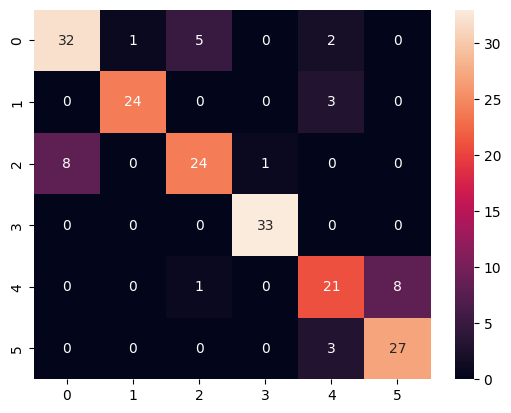

In [2]:
# 1. Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
evaluate_model(nb_model, X_test, y_test)

Accuracy: 0.9015544041450777
Precision: 0.9057615176123363
Recall: 0.9015544041450777
F1 Score: 0.9028363828119355
Confusion Matrix:
 [[37  0  3  0  0  0]
 [ 0 25  0  0  2  0]
 [ 3  0 28  1  1  0]
 [ 0  0  3 30  0  0]
 [ 0  0  1  0 27  2]
 [ 0  0  0  0  3 27]]


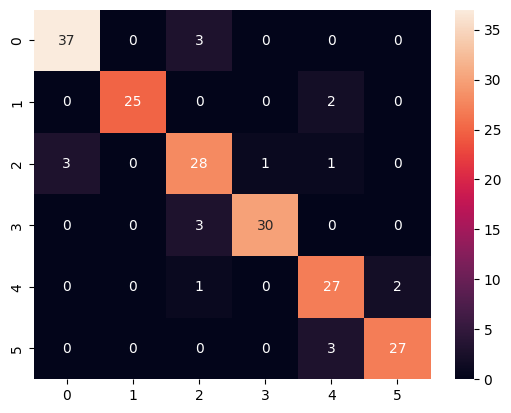

In [3]:
# 2. Support Vector Machine
svm_model = SVC()
svm_model.fit(X_train, y_train)
evaluate_model(svm_model, X_test, y_test)

Accuracy: 0.7927461139896373
Precision: 0.7967563512214533
Recall: 0.7927461139896373
F1 Score: 0.7934500782026054
Confusion Matrix:
 [[29  1  9  0  0  1]
 [ 0 22  0  0  4  1]
 [ 6  1 22  1  1  2]
 [ 1  0  3 29  0  0]
 [ 1  2  0  0 24  3]
 [ 0  0  0  0  3 27]]


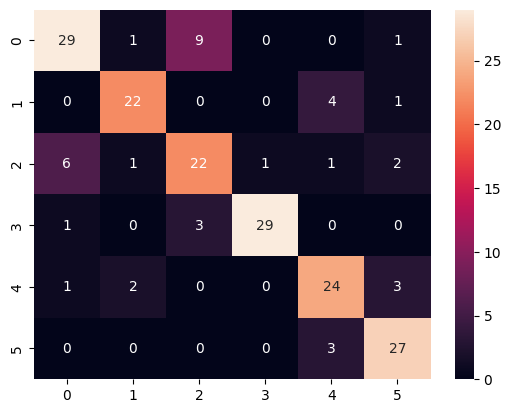

In [4]:
# 3. Decision Tree
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)
evaluate_model(dt_model, X_test, y_test)

Accuracy: 0.9326424870466321
Precision: 0.9339206182222178
Recall: 0.9326424870466321
F1 Score: 0.9330111622626369
Confusion Matrix:
 [[38  0  2  0  0  0]
 [ 0 25  0  0  2  0]
 [ 2  0 30  1  0  0]
 [ 0  0  1 32  0  0]
 [ 0  0  1  0 27  2]
 [ 0  0  0  0  2 28]]


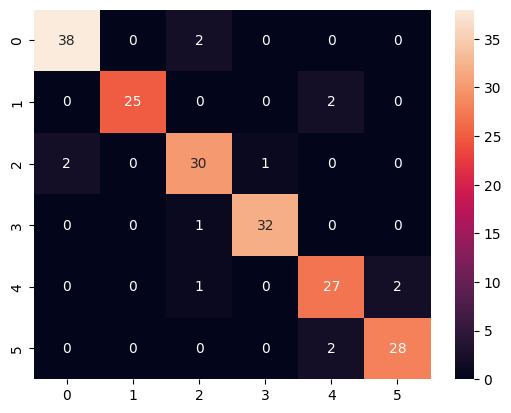

In [5]:
# 4. Random Forest
rf_model = RandomForestClassifier()
rf_model.fit(X_train, y_train)
evaluate_model(rf_model, X_test, y_test)

/Users/kshitijsharma/ml_envs/tensorflow-gpu/lib/python3.10/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-03-21 14:16:06.960618: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2 Pro
2025-03-21 14:16:06.960658: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2025-03-21 14:16:06.960667: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2025-03-21 14:16:06.960688: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-03-21 14:16:06.960705: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_fa

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step - accuracy: 0.9069 - loss: 0.2843
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Accuracy: 0.917098445595855
Precision: 0.9203077806676484
Recall: 0.917098445595855
F1 Score: 0.9179949313496564
Confusion Matrix:
 [[38  0  2  0  0  0]
 [ 1 25  0  0  0  1]
 [ 0  0 29  1  1  2]
 [ 0  0  3 30  0  0]
 [ 0  0  0  0 28  2]
 [ 0  0  0  0  3 27]]


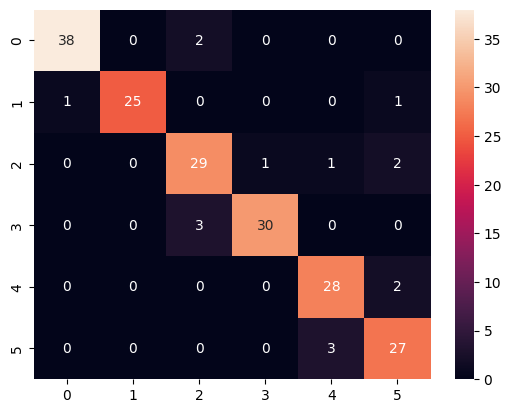

In [6]:
# 5. Artificial Neural Network

def evaluate_model(model, X_test, y_test, labels=None):
    # Handle ANN/CNN differently — check if output is probabilistic
    y_pred = model.predict(X_test)
    if len(y_pred.shape) > 1 and y_pred.shape[1] > 1:
        y_pred = np.argmax(y_pred, axis=1)  # Convert softmax output to class labels
    
    # Compute metrics
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, average='weighted', zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, average='weighted', zero_division=0))
    print("F1 Score:", f1_score(y_test, y_pred, average='weighted', zero_division=0))
    
    # Ensure confusion matrix includes all labels even if missing in predictions
    cm = confusion_matrix(y_test, y_pred, labels=labels if labels else np.unique(y_test))
    print("Confusion Matrix:\n", cm)
    sns.heatmap(cm, annot=True, fmt='d')
    plt.show()

ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(len(np.unique(y)), activation='softmax')
])
ann_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
ann_model.fit(X_train, y_train, epochs=20, batch_size=16, verbose=0)
ann_eval = ann_model.evaluate(X_test, y_test)
y_pred_ann = np.argmax(ann_model.predict(X_test), axis=1)
evaluate_model(ann_model, X_test, y_test)

/Users/kshitijsharma/ml_envs/tensorflow-gpu/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.9025 - loss: 0.3196
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Accuracy: 0.9067357512953368
Precision: 0.9110759508924091
Recall: 0.9067357512953368
F1 Score: 0.9079250439965496
Confusion Matrix:
 [[36  0  3  0  0  1]
 [ 0 25  1  0  1  0]
 [ 2  1 29  1  0  0]
 [ 0  0  3 30  0  0]
 [ 0  0  1  0 28  1]
 [ 0  0  0  0  3 27]]


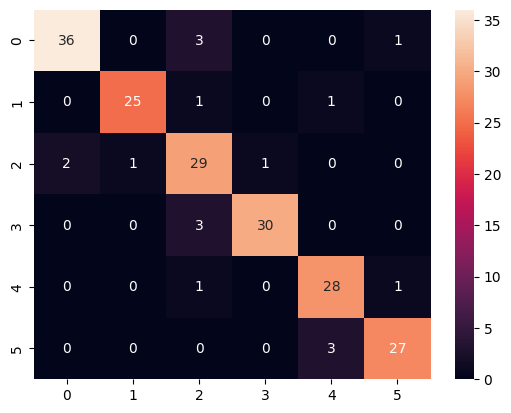

In [7]:
# 6. Convolutional Neural Network (1D for feature data)
X_train_cnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_cnn = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

cnn_model = Sequential([
    Conv1D(32, kernel_size=3, activation='relu', input_shape=(X_train.shape[1], 1)),
    MaxPooling1D(2),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(len(np.unique(y)), activation='softmax')
])
cnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn_model.fit(X_train_cnn, y_train, epochs=20, batch_size=16, verbose=0)
cnn_eval = cnn_model.evaluate(X_test_cnn, y_test)
y_pred_cnn = np.argmax(cnn_model.predict(X_test_cnn), axis=1)
evaluate_model(cnn_model, X_test_cnn, y_test)